
# Month 2 – Task 4: Netflix Titles Dataset – Exploratory Analysis & Insights

## Project Objective

Explore the Netflix Titles dataset to identify media content trends, content types, and popular countries.

## Objectives
- Understand and clean the Netflix dataset
- Work with date and time data
- Handle missing values in director and cast columns
- Create release_decade and is_movie features
- Extract release_year and content_type
- Identify the top 5 countries by content popularity
- Perform data visualization and exploratory analysis
- Summarize key findings and their business meaning



## 1. Data Understanding

In this section, the Netflix Titles dataset is loaded and inspected to understand its structure, dimensions, column names, data types, and missing values.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from google.colab import files

uploaded = files.upload()

file_name = next(iter(uploaded))

df = pd.read_csv(file_name)

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

print("\nFirst 5 Rows:")
display(df.head())

Saving netflix_titles.csv to netflix_titles.csv
Dataset loaded successfully!
Dataset Shape: (8807, 12)

First 5 Rows:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


In [2]:
print("Dataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe(include="all"))

print("\nColumn Names:")
print(df.columns.tolist())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8807 entries, 0 to 8806
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8807 non-null   object
 1   type          8807 non-null   object
 2   title         8807 non-null   object
 3   director      6173 non-null   object
 4   cast          7982 non-null   object
 5   country       7976 non-null   object
 6   date_added    8797 non-null   object
 7   release_year  8807 non-null   int64 
 8   rating        8803 non-null   object
 9   duration      8804 non-null   object
 10  listed_in     8807 non-null   object
 11  description   8807 non-null   object
dtypes: int64(1), object(11)
memory usage: 825.8+ KB

Statistical Summary:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s8807,Movie,Zubaan,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned prope..."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN



Column Names:
['show_id', 'type', 'title', 'director', 'cast', 'country', 'date_added', 'release_year', 'rating', 'duration', 'listed_in', 'description']

Missing Values:
show_id            0
type               0
title              0
director        2634
cast             825
country          831
date_added        10
release_year       0
rating             4
duration           3
listed_in          0
description        0
dtype: int64


## 2. Data Cleaning

In this section, missing values in the director and cast columns are handled, and the date_added column is converted into datetime format for further analysis.

In [3]:
# Create a copy to preserve the original dataset
df_clean = df.copy()

# Fill missing values in director and cast
df_clean["director"] = df_clean["director"].fillna("Not Available")
df_clean["cast"] = df_clean["cast"].fillna("Not Available")

# Convert date_added into datetime format
df_clean["date_added"] = pd.to_datetime(
    df_clean["date_added"],
    errors="coerce"
)

# Check the changes
print("Missing Values After Cleaning:")
print(df_clean.isnull().sum())

print("\nUpdated Data Types:")
print(df_clean.dtypes)

print("\nFirst 5 Rows After Cleaning:")
display(df_clean.head())

Missing Values After Cleaning:
show_id           0
type              0
title             0
director          0
cast              0
country         831
date_added       98
release_year      0
rating            4
duration          3
listed_in         0
description       0
dtype: int64

Updated Data Types:
show_id                 object
type                    object
title                   object
director                object
cast                    object
country                 object
date_added      datetime64[ns]
release_year             int64
rating                  object
duration                object
listed_in               object
description             object
dtype: object

First 5 Rows After Cleaning:


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,Not Available,United States,2021-09-25,2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmm..."
1,s2,TV Show,Blood & Water,Not Available,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thaban...",South Africa,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town t..."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabi...",NaN,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",To protect his family from a powerful drug lor...
3,s4,TV Show,Jailbirds New Orleans,Not Available,Not Available,NaN,2021-09-24,2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down amo..."
4,s5,TV Show,Kota Factory,Not Available,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam K...",India,2021-09-24,2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV ...",In a city of coaching centers known to train I...


## 3. Feature Engineering

In this section, new features are created to support content trend analysis. These include release decade, movie identification, content type, and the year in which Netflix added each title.

In [4]:
# Create release decade
df_clean["release_decade"] = (
    (df_clean["release_year"] // 10) * 10
).astype(str) + "s"

# Create is_movie feature
df_clean["is_movie"] = (
    df_clean["type"] == "Movie"
).astype(int)

# Create content_type feature
df_clean["content_type"] = df_clean["type"]

# Extract year from date_added
df_clean["date_added_year"] = df_clean["date_added"].dt.year

# Display the newly created features
display(
    df_clean[
        ["title", "type", "release_year", "release_decade",
         "is_movie", "content_type", "date_added_year"]
    ].head(10)
)

print("\nNew Dataset Shape:", df_clean.shape)

,title,type,release_year,release_decade,is_movie,content_type,date_added_year
0,Dick Johnson Is Dead,Movie,2020,2020s,1,Movie,2021.0
1,Blood & Water,TV Show,2021,2020s,0,TV Show,2021.0
2,Ganglands,TV Show,2021,2020s,0,TV Show,2021.0
3,Jailbirds New Orleans,TV Show,2021,2020s,0,TV Show,2021.0
4,Kota Factory,TV Show,2021,2020s,0,TV Show,2021.0
5,Midnight Mass,TV Show,2021,2020s,0,TV Show,2021.0
6,My Little Pony: A New Generation,Movie,2021,2020s,1,Movie,2021.0
7,Sankofa,Movie,1993,1990s,1,Movie,2021.0
8,The Great British Baking Show,TV Show,2021,2020s,0,TV Show,2021.0
9,The Starling,Movie,2021,2020s,1,Movie,2021.0



New Dataset Shape: (8807, 16)


## 4. Exploratory Data Analysis (EDA)

### 4.1 Movie vs TV Show Distribution

Analyze the distribution of movies and TV shows available in the Netflix dataset.

Content Type Distribution:


,count
content_type,
Movie,6131
TV Show,2676


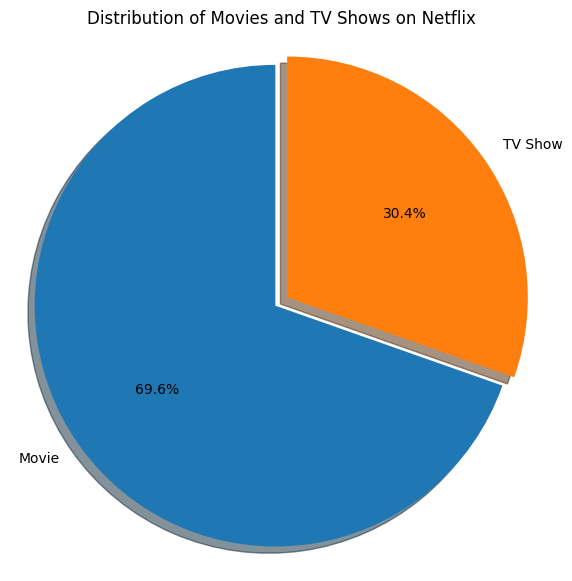

In [5]:
# Count movies and TV shows
content_counts = df_clean["content_type"].value_counts()

print("Content Type Distribution:")
display(content_counts)

# Create pie chart
plt.figure(figsize=(7, 7))

plt.pie(
    content_counts,
    labels=content_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    explode=[0.03] * len(content_counts),
    shadow=True
)

plt.title("Distribution of Movies and TV Shows on Netflix")
plt.axis("equal")
plt.show()

#### What does this mean?

- Movies account for 69.6% of the Netflix catalogue, while TV Shows account for 30.4%.
- Movies represent the larger portion of the available content.
- This indicates that Netflix has a considerably larger movie catalogue than TV Show catalogue.

### 4.2 Year-wise Content Release Trends

Analyze the number of Netflix titles released each year to identify changes in content production and release trends over time.

,release_year,content_count
59,2007,88
60,2008,136
61,2009,152
62,2010,194
63,2011,185
64,2012,237
65,2013,288
66,2014,352
67,2015,560
68,2016,902


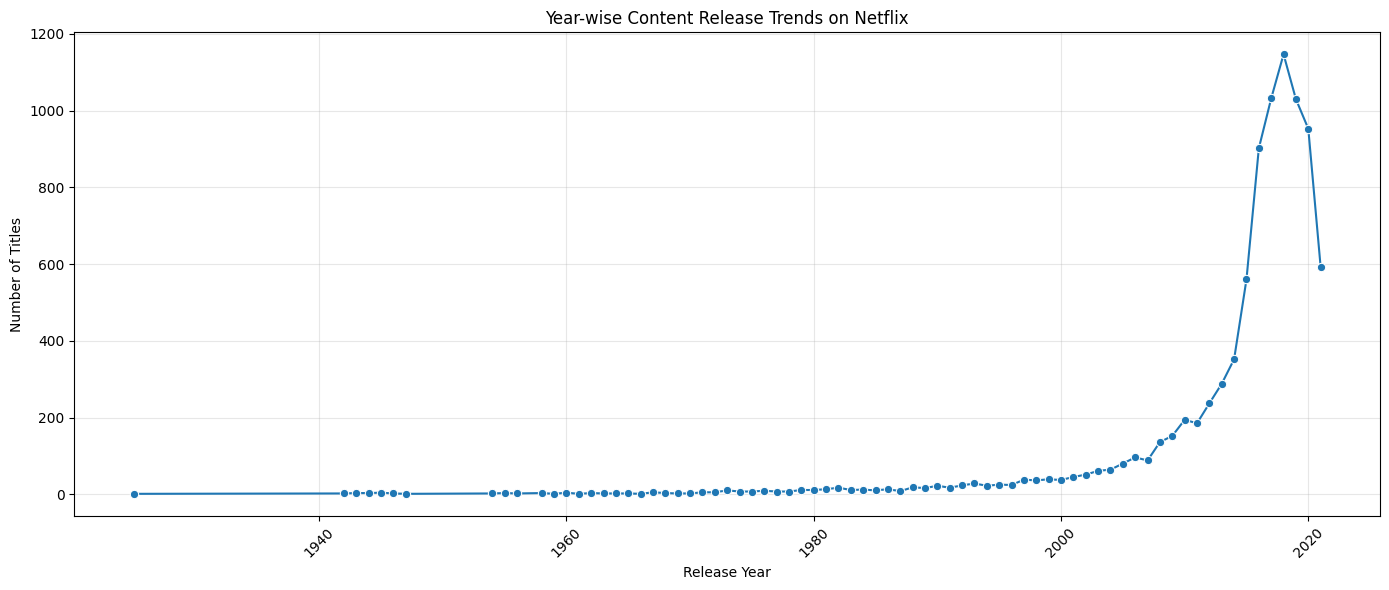

In [6]:
# Count content released each year
yearly_content = (
    df_clean.groupby("release_year")
    .size()
    .reset_index(name="content_count")
)

# Sort by release year
yearly_content = yearly_content.sort_values("release_year")

# Display the latest 15 years
display(yearly_content.tail(15))

# Create line plot
plt.figure(figsize=(14, 6))

sns.lineplot(
    data=yearly_content,
    x="release_year",
    y="content_count",
    marker="o"
)

plt.title("Year-wise Content Release Trends on Netflix")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#### What does this mean?

- Content releases increased significantly from 2007 onwards.
- The highest count in the displayed data is 1,147 titles in 2018.
- The count declined to 1,030 in 2019, 953 in 2020, and 592 in 2021.
- The dataset shows a growing concentration of titles released during the 2010s.
- The decline in later years should be interpreted carefully because this dataset only represents titles available in the Netflix catalogue.

### 4.3 Top 10 Genres on Netflix

Identify the most frequently occurring genres in the Netflix catalogue by splitting the multi-label listed_in column.

Top 10 Genres on Netflix:


,count
listed_in,
International Movies,2752
Dramas,2427
Comedies,1674
International TV Shows,1351
Documentaries,869
Action & Adventure,859
TV Dramas,763
Independent Movies,756
Children & Family Movies,641


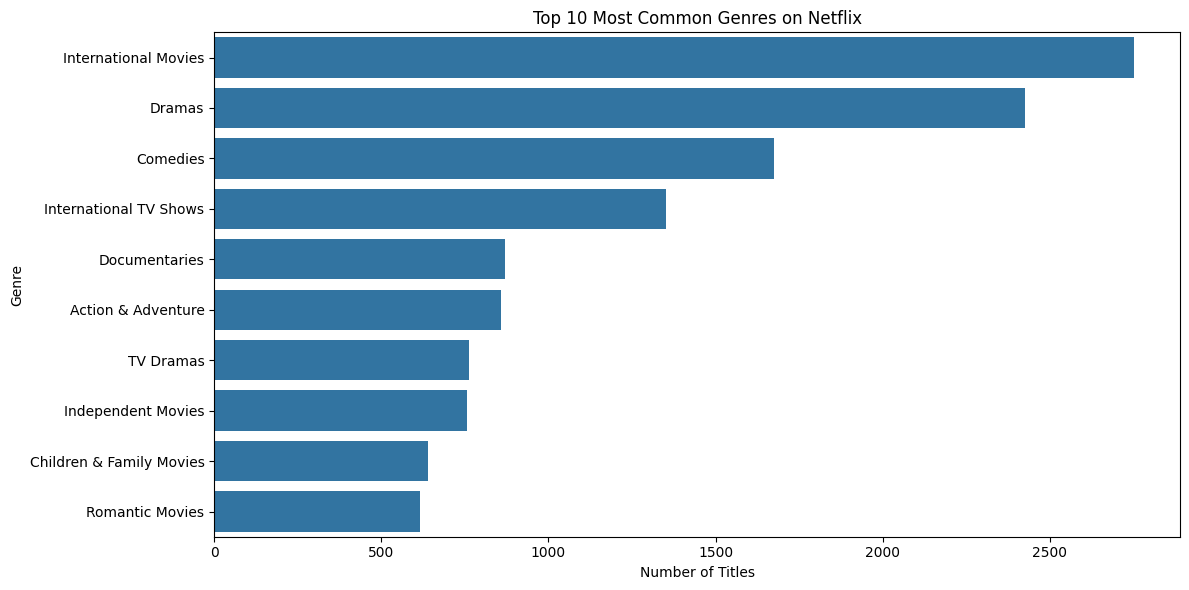

In [7]:
# Split multiple genres and count their occurrences
genre_counts = (
    df_clean["listed_in"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
)

# Select top 10 genres
top_10_genres = genre_counts.head(10)

print("Top 10 Genres on Netflix:")
display(top_10_genres)

# Create bar plot
plt.figure(figsize=(12, 6))

sns.barplot(
    x=top_10_genres.values,
    y=top_10_genres.index
)

plt.title("Top 10 Most Common Genres on Netflix")
plt.xlabel("Number of Titles")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

#### What does this mean?

- International Movies are the most frequently listed genre, with 2,752 titles.
- Dramas rank second with 2,427 titles, followed by Comedies with 1,674 titles.
- International TV Shows rank fourth with 1,351 titles.
- Documentaries and Action & Adventure have similar counts.
- This indicates strong representation of international content, drama, and comedy in Netflix's catalogue.

### 4.4 Country-wise Content Analysis

Identify the top 5 countries contributing content to Netflix and compare their Movie and TV Show volumes.

In [8]:
# Split country names and count individual country occurrences
country_counts = (
    df_clean["country"]
    .dropna()
    .str.split(",")
    .explode()
    .str.strip()
    .value_counts()
)

# Identify top 5 countries
top_5_countries = country_counts.head(5)

print("Top 5 Countries by Content Volume:")
display(top_5_countries)

Top 5 Countries by Content Volume:


,count
country,
United States,3690
India,1046
United Kingdom,806
Canada,445
France,393


Country-wise Content Type Distribution:


content_type,Movie,TV Show
country,,
Canada,319,126
France,303,90
India,962,84
United Kingdom,534,272
United States,2752,938


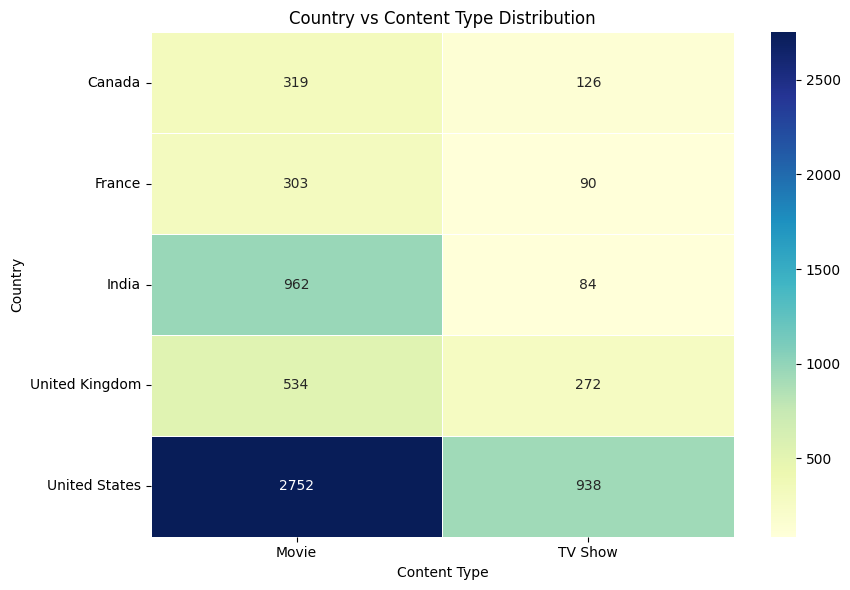

In [9]:
# Split country values into individual countries
country_data = df_clean[["country", "content_type"]].dropna().copy()

country_data["country"] = country_data["country"].str.split(",")

country_data = country_data.explode("country")

country_data["country"] = country_data["country"].str.strip()

# Filter the top 5 countries
country_data = country_data[
    country_data["country"].isin(top_5_countries.index)
]

# Create country vs content type table
country_content = pd.crosstab(
    country_data["country"],
    country_data["content_type"]
)

print("Country-wise Content Type Distribution:")
display(country_content)

# Create heatmap
plt.figure(figsize=(9, 6))

sns.heatmap(
    country_content,
    annot=True,
    fmt="d",
    cmap="YlGnBu",
    linewidths=0.5
)

plt.title("Country vs Content Type Distribution")
plt.xlabel("Content Type")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

#### What does this mean?

- The United States has the highest number of both Movies and TV Shows among the top five countries.
- India has 962 Movies and 84 TV Shows, showing a strong representation of movies.
- The United Kingdom has a comparatively balanced distribution, with 534 Movies and 272 TV Shows.
- Canada and France also have more Movies than TV Shows.
- This indicates that the content distribution differs across countries, with movies dominating in all five countries.

### 4.5 Content Distribution by Release Decade

Analyze how Netflix titles are distributed across different release decades.

Content Distribution by Release Decade:


,count
release_decade,
1920s,1
1940s,15
1950s,11
1960s,25
1970s,70
1980s,129
1990s,274
2000s,810
2010s,5927


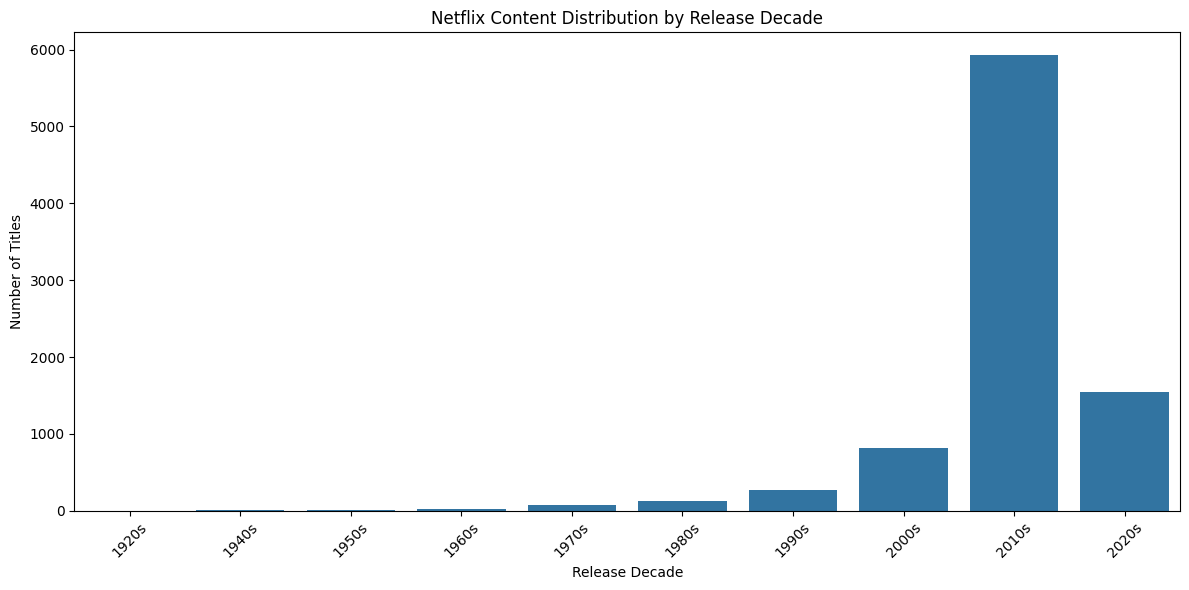

In [10]:
# Count titles by release decade
decade_counts = (
    df_clean["release_decade"]
    .value_counts()
    .sort_index()
)

print("Content Distribution by Release Decade:")
display(decade_counts)

# Create bar chart
plt.figure(figsize=(12, 6))

sns.barplot(
    x=decade_counts.index,
    y=decade_counts.values
)

plt.title("Netflix Content Distribution by Release Decade")
plt.xlabel("Release Decade")
plt.ylabel("Number of Titles")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#### What does this mean?

- The 2010s have the highest representation, with 5,927 titles.
- The 2020s account for 1,545 titles in the dataset.
- The 2000s contribute 810 titles.
- Earlier decades have considerably fewer titles.
- This indicates that Netflix's catalogue is heavily concentrated in content released during the 2010s and 2020s.
- The 2020s figure covers only the years represented in this dataset, not the entire decade.

## 5. Key Insights and Business Interpretation

### 1. Movie vs TV Show Distribution
Movies account for 69.6% of the Netflix catalogue, while TV Shows account for 30.4%. This indicates that movies form the larger portion of the available content.

### 2. Year-wise Content Release Trends
The number of titles increased significantly over time, reaching its highest displayed value of 1,147 in 2018. The count declined in 2019, 2020, and 2021.

### 3. Genre Popularity
International Movies, Dramas, and Comedies are the three most frequently listed genres. This indicates strong representation of international content and drama-based entertainment.

### 4. Country-wise Content Distribution
The United States contributes the highest number of titles, followed by India and the United Kingdom. The United States also has the highest number of Movies and TV Shows among the top five countries.

### 5. Release Decade Trends
The 2010s have the largest representation, with 5,927 titles. This shows that the Netflix catalogue is strongly concentrated in relatively recent content.

## 6. Overall Conclusion

The exploratory analysis of the Netflix Titles dataset reveals that movies dominate the catalogue, international movies and dramas are highly represented, and the United States is the leading content contributor. Most titles in the dataset were released during the 2010s.

These findings help explain the composition of Netflix's content catalogue and provide an overview of its genre, country, and release-year distribution.

## 7. Final Dataset Verification

Verify the cleaned dataset, engineered features, and key analysis results before completing the project.

In [11]:
# Final dataset verification

print("FINAL PROJECT VERIFICATION")
print("-" * 40)

print("Original Dataset Shape:", df.shape)
print("Cleaned Dataset Shape:", df_clean.shape)

print("\nRequired Features:")
required_features = [
    "release_decade",
    "is_movie",
    "content_type",
    "date_added_year"
]

for feature in required_features:
    print(feature, ":", feature in df_clean.columns)

print("\nDate Added Data Type:")
print(df_clean["date_added"].dtype)

print("\nMissing Director Values:",
      df_clean["director"].isnull().sum())

print("Missing Cast Values:",
      df_clean["cast"].isnull().sum())

print("\nContent Type Counts:")
print(df_clean["content_type"].value_counts())

print("\nTop 5 Countries:")
print(top_5_countries)

print("\nTop 10 Genres:")
print(top_10_genres)

print("\nFinal Verification Completed!")

FINAL PROJECT VERIFICATION
----------------------------------------
Original Dataset Shape: (8807, 12)
Cleaned Dataset Shape: (8807, 16)

Required Features:
release_decade : True
is_movie : True
content_type : True
date_added_year : True

Date Added Data Type:
datetime64[ns]

Missing Director Values: 0
Missing Cast Values: 0

Content Type Counts:
content_type
Movie      6131
TV Show    2676
Name: count, dtype: int64

Top 5 Countries:
country
United States     3690
India             1046
United Kingdom     806
Canada             445
France             393
Name: count, dtype: int64

Top 10 Genres:
listed_in
International Movies        2752
Dramas                      2427
Comedies                    1674
International TV Shows      1351
Documentaries                869
Action & Adventure           859
TV Dramas                    763
Independent Movies           756
Children & Family Movies     641
Romantic Movies              616
Name: count, dtype: int64

Final Verification Completed!


## 8. Bonus: Netflix Content Trend Prediction

Use Linear Regression on historical yearly content counts to estimate the number of titles for the next two years. These predictions are exploratory and should not be treated as actual future content counts.

Netflix Content Trend Prediction:


,Year,Predicted Content Count
0,2022,383
1,2023,390


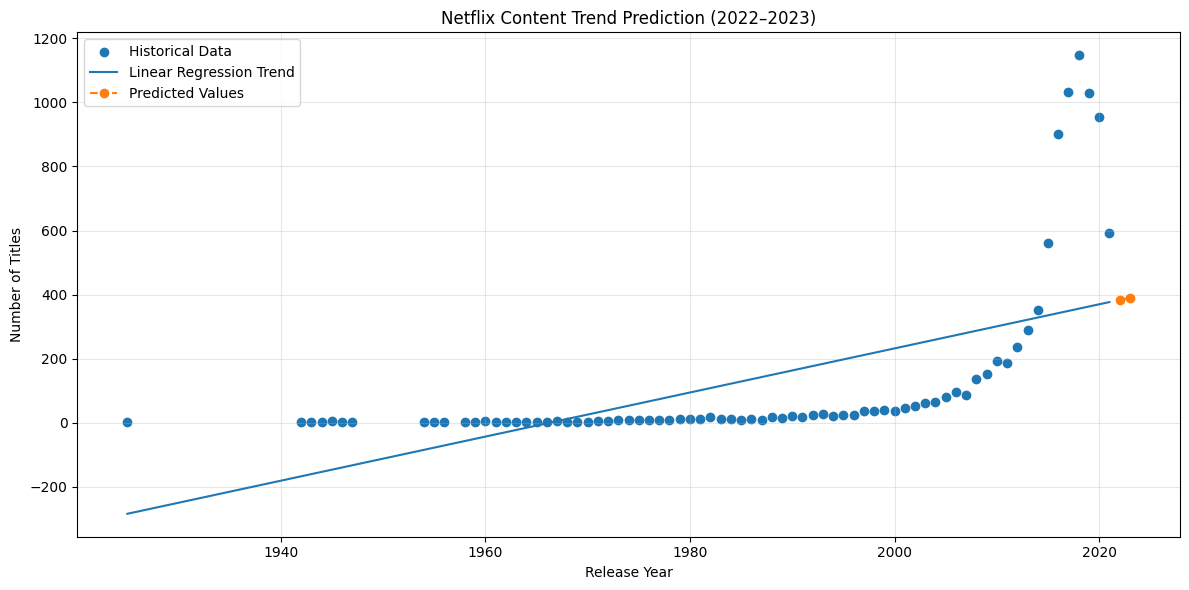

In [12]:
from sklearn.linear_model import LinearRegression

# Prepare historical yearly content data
trend_data = yearly_content.copy()

X = trend_data[["release_year"]]
y = trend_data["content_count"]

# Train Linear Regression model
trend_model = LinearRegression()
trend_model.fit(X, y)

# Predict content counts for the next two years
future_years = pd.DataFrame({
    "release_year": [2022, 2023]
})

predictions = trend_model.predict(future_years)

# Display predictions
prediction_results = pd.DataFrame({
    "Year": future_years["release_year"],
    "Predicted Content Count": predictions.round().astype(int)
})

print("Netflix Content Trend Prediction:")
display(prediction_results)

# Plot historical data and predictions
plt.figure(figsize=(12, 6))

plt.scatter(
    trend_data["release_year"],
    trend_data["content_count"],
    label="Historical Data"
)

plt.plot(
    trend_data["release_year"],
    trend_model.predict(X),
    label="Linear Regression Trend"
)

plt.plot(
    future_years["release_year"],
    predictions,
    marker="o",
    linestyle="--",
    label="Predicted Values"
)

plt.title("Netflix Content Trend Prediction (2022–2023)")
plt.xlabel("Release Year")
plt.ylabel("Number of Titles")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Bonus Prediction Insights

A Linear Regression model was used to estimate Netflix content trends for 2022 and 2023.

- Predicted content count for 2022: 383
- Predicted content count for 2023: 390

The model indicates a slight increase in the predicted number of titles. However, the predictions are limited by the simple linear relationship used and the large variation in historical content counts.

These results are exploratory estimates and should not be considered actual Netflix release figures.